# 12_ROCOv2_Evaluation

**Purpose:** Consolidate every result produced across Notebooks 05–11 into
one comprehensive, thesis-ready comparison — point-prediction accuracy,
conformal calibration/efficiency, counterfactual robustness, and trust
score — culminating in a single trustworthiness scorecard.

### Scope (stated explicitly, not assumed)
- **Descriptive synthesis only.** This notebook aggregates and presents
  already-computed results; it does not run any significance test or
  confidence interval — that's the explicit job of the next notebook,
  `13_ROCOv2_Statistical_Analysis.ipynb`.
- **No model is loaded, no inference is re-run, nothing is retrained.**
  Every number here is read from an existing artifact.
- Point-prediction metrics are read from **Notebook 08's**
  `test_final_point_metrics_all_models.csv` — not re-derived from each
  model's own individually-saved metrics files — because that's the one
  artifact where all three models were already evaluated on the exact same
  Test-final subset, apples-to-apples. Mixing in 05/06/07's original
  full-Test numbers here would silently compare different Test sets.

### Inputs
- `Prepared/ConformalPrediction/test_final_point_metrics_all_models.csv`,
  `conformal_summary_all_models.csv`, `conformal_per_label_results.csv` (08)
- `Prepared/CounterfactualExplanations/counterfactual_distance_summary.csv` (09)
- `Prepared/TrustScore/trust_score_per_label_summary.csv`,
  `trust_score_config.json` (11)

### Outputs
Under `Prepared/Evaluation/`: consolidated comparison tables and figures,
and the master trustworthiness scorecard, plus config/reproducibility/
manifest.

### Non-goals
No significance testing (Notebook 13). No new model training or
inference. No modification of any previous notebook or artifact.

In [ ]:
# ============================================================
# CELL 1 — CONFIGURATION, PATHS, AND REPRODUCIBILITY
# ============================================================

import sys
import json
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IN_COLAB = True
    print("Google Drive available.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

ROCO_ROOT = Path("/content/drive/MyDrive/ROCOv2")
PREPARED_DIR = ROCO_ROOT / "Prepared"

EVAL_DIR = PREPARED_DIR / "Evaluation"
FIG_DIR = EVAL_DIR / "figures"
for d in [EVAL_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

POINT_METRICS_PATH = PREPARED_DIR / "ConformalPrediction" / "test_final_point_metrics_all_models.csv"
CONFORMAL_SUMMARY_PATH = PREPARED_DIR / "ConformalPrediction" / "conformal_summary_all_models.csv"
CONFORMAL_PER_LABEL_PATH = PREPARED_DIR / "ConformalPrediction" / "conformal_per_label_results.csv"
COUNTERFACTUAL_SUMMARY_PATH = PREPARED_DIR / "CounterfactualExplanations" / "counterfactual_distance_summary.csv"
TRUST_SUMMARY_PATH = PREPARED_DIR / "TrustScore" / "trust_score_per_label_summary.csv"
TRUST_CONFIG_PATH = PREPARED_DIR / "TrustScore" / "trust_score_config.json"

POINT_METRICS_FIGURE_PDF = FIG_DIR / "point_metrics_comparison.pdf"
POINT_METRICS_FIGURE_PNG = FIG_DIR / "point_metrics_comparison_300dpi.png"
SCORECARD_PATH = EVAL_DIR / "trustworthiness_scorecard.csv"
CONFORMAL_TABLE_PATH = EVAL_DIR / "conformal_comparison.csv"
COUNTERFACTUAL_TABLE_PATH = EVAL_DIR / "counterfactual_robustness_summary.csv"
TRUST_TABLE_PATH = EVAL_DIR / "trust_score_summary.csv"
EVAL_CONFIG_PATH = EVAL_DIR / "evaluation_config.json"
REPRODUCIBILITY_PATH = EVAL_DIR / "reproducibility.json"
MANIFEST_PATH = EVAL_DIR / "artifact_manifest.json"

ALLOW_OVERWRITE = False

def safe_save_json(path, obj, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    print("Saved:", path)

def safe_save_csv(path, df, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    df.to_csv(path, index=False)
    print("Saved:", path)

print("=" * 80)
print("NOTEBOOK 12 — EVALUATION (CONSOLIDATED COMPARISON)")
print("=" * 80)
print("ROCO_ROOT:", ROCO_ROOT)
print("EVAL_DIR:", EVAL_DIR)


Mounted at /content/drive
Google Drive available.
NOTEBOOK 12 — EVALUATION (CONSOLIDATED COMPARISON)
ROCO_ROOT: /content/drive/MyDrive/ROCOv2
EVAL_DIR: /content/drive/MyDrive/ROCOv2/Prepared/Evaluation


## 1. Verify required inputs

In [ ]:
# ============================================================
# CELL 2 — REQUIRED INPUT ARTIFACT CHECK
# ============================================================

required_inputs = {
    "test_final_point_metrics_all_models.csv": POINT_METRICS_PATH,
    "conformal_summary_all_models.csv": CONFORMAL_SUMMARY_PATH,
    "conformal_per_label_results.csv": CONFORMAL_PER_LABEL_PATH,
    "counterfactual_distance_summary.csv": COUNTERFACTUAL_SUMMARY_PATH,
    "trust_score_per_label_summary.csv": TRUST_SUMMARY_PATH,
    "trust_score_config.json": TRUST_CONFIG_PATH,
}
missing_inputs = [f"{name}: {path}" for name, path in required_inputs.items() if not path.exists()]
if missing_inputs:
    raise FileNotFoundError(
        "Required Notebook 12 input artifacts are missing:\n\n" + "\n".join(missing_inputs)
        + "\n\nRun 08, 09, and 11 first."
    )

print("PASS — Required Notebook 08/09/11 artifacts exist.")
for name, path in required_inputs.items():
    print(f"{name:50s}: {path}")


PASS — Required Notebook 08/09/11 artifacts exist.
test_final_point_metrics_all_models.csv           : /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/test_final_point_metrics_all_models.csv
conformal_summary_all_models.csv                  : /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/conformal_summary_all_models.csv
conformal_per_label_results.csv                   : /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/conformal_per_label_results.csv
counterfactual_distance_summary.csv               : /content/drive/MyDrive/ROCOv2/Prepared/CounterfactualExplanations/counterfactual_distance_summary.csv
trust_score_per_label_summary.csv                 : /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/trust_score_per_label_summary.csv
trust_score_config.json                           : /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/trust_score_config.json


## 2. Load all consolidated results

In [ ]:
# ============================================================
# CELL 3 — LOAD EVERYTHING
# ============================================================

point_metrics_df = pd.read_csv(POINT_METRICS_PATH)
conformal_summary_df = pd.read_csv(CONFORMAL_SUMMARY_PATH)
conformal_per_label_df = pd.read_csv(CONFORMAL_PER_LABEL_PATH)
counterfactual_summary_df = pd.read_csv(COUNTERFACTUAL_SUMMARY_PATH)
trust_summary_df = pd.read_csv(TRUST_SUMMARY_PATH)

with open(TRUST_CONFIG_PATH, "r", encoding="utf-8") as f:
    trust_config = json.load(f)

print(f"Point-prediction metrics: {len(point_metrics_df)} model(s)")
print(f"Conformal summary: {len(conformal_summary_df)} model(s)")
print(f"Counterfactual summary: {len(counterfactual_summary_df)} label(s) (Proposed VLM only)")
print(f"Trust score summary: {len(trust_summary_df)} label(s) (Proposed VLM only)")


Point-prediction metrics: 3 model(s)
Conformal summary: 3 model(s)
Counterfactual summary: 18 label(s) (Proposed VLM only)
Trust score summary: 18 label(s) (Proposed VLM only)


## 3. Point-prediction comparison (Test-final, all three models)

Already apples-to-apples from Notebook 08 — same Test-final subset for
every model, nothing re-derived here.

In [ ]:
# ============================================================
# CELL 4 — POINT-PREDICTION COMPARISON TABLE
# ============================================================

display_cols = ["Model", "Micro_F1", "Macro_F1", "ROC_AUC_Macro", "Hamming_Loss", "Subset_Accuracy"]
point_comparison_df = point_metrics_df[display_cols].copy()

best_macro_f1_model = point_comparison_df.loc[point_comparison_df["Macro_F1"].idxmax(), "Model"]
print(f"Best Macro-F1 on Test-final: {best_macro_f1_model}")
display(point_comparison_df)


Best Macro-F1 on Test-final: Proposed VLM (fine-tuned BiomedCLIP)


,Model,Micro_F1,Macro_F1,ROC_AUC_Macro,Hamming_Loss,Subset_Accuracy
0,DenseNet121 (image-only baseline),0.857775,0.717013,0.969709,0.026039,0.664640
1,BiomedCLIP (zero-shot VLM baseline),0.160983,0.147950,0.665886,0.912000,0.000000
2,Proposed VLM (fine-tuned BiomedCLIP),0.928526,0.831051,0.995362,0.012631,0.863425


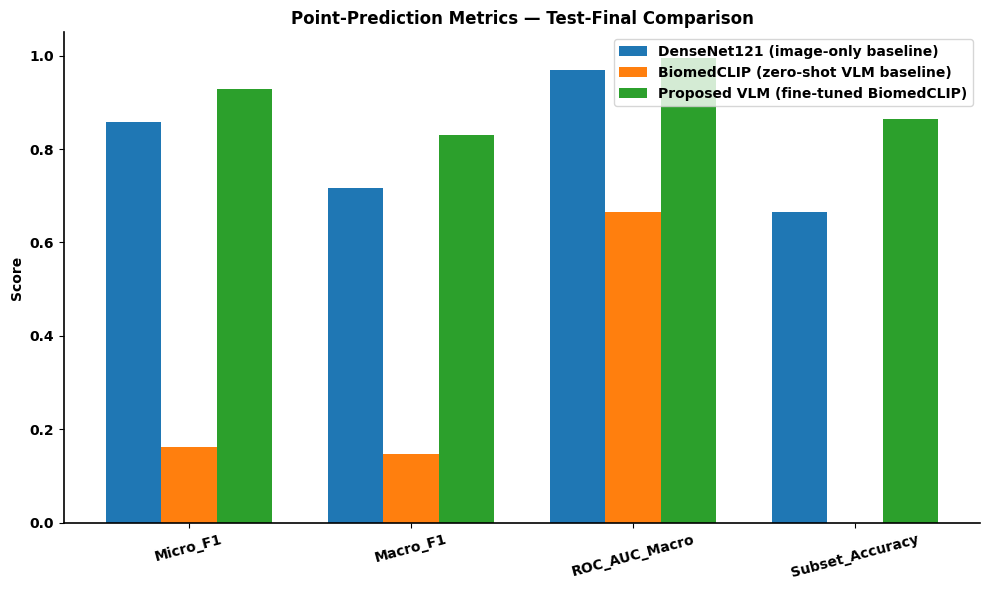

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Evaluation/figures/point_metrics_comparison.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Evaluation/figures/point_metrics_comparison_300dpi.png


In [ ]:
# ============================================================
# CELL 5 — POINT-PREDICTION COMPARISON FIGURE
# ============================================================

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.linewidth": 1.2,
})

metrics_to_plot = ["Micro_F1", "Macro_F1", "ROC_AUC_Macro", "Subset_Accuracy"]
x = np.arange(len(metrics_to_plot))
width = 0.25
colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

fig, ax = plt.subplots(figsize=(10, 6))
for i, (_, row) in enumerate(point_metrics_df.iterrows()):
    values = [row[m] for m in metrics_to_plot]
    ax.bar(x + (i - 1) * width, values, width, label=row["Model"], color=colors[i % len(colors)])

ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot, rotation=15)
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Point-Prediction Metrics — Test-Final Comparison", fontweight="bold")
ax.legend(frameon=True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(POINT_METRICS_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(POINT_METRICS_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", POINT_METRICS_FIGURE_PDF)
print("Saved:", POINT_METRICS_FIGURE_PNG)


## 4. Conformal calibration and efficiency comparison

Reproduced from Notebook 08's summary — target coverage 90% (α=0.10),
per-label LAC prediction sets.

In [ ]:
# ============================================================
# CELL 6 — CONFORMAL COMPARISON TABLE
# ============================================================

safe_save_csv(CONFORMAL_TABLE_PATH, conformal_summary_df)
display(conformal_summary_df)

most_efficient_model = conformal_summary_df.loc[
    conformal_summary_df["Mean_Set_Size_Across_Labels"].idxmin(), "Model"
]
print(f"\nMost efficient (smallest mean prediction-set size): {most_efficient_model}")


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Evaluation/conformal_comparison.csv


,Model,Mean_Coverage_Across_Labels,Min_Coverage_Across_Labels,Mean_Set_Size_Across_Labels,Labels_Notably_Below_Target_(>2pt)
0,DenseNet121 (image-only baseline),0.902173,0.887741,0.914590,0
1,BiomedCLIP (zero-shot VLM baseline),1.000000,1.000000,2.000000,0
2,Proposed VLM (fine-tuned BiomedCLIP),0.910571,0.896454,0.912406,0



Most efficient (smallest mean prediction-set size): Proposed VLM (fine-tuned BiomedCLIP)


## 5. Counterfactual robustness summary (Proposed VLM)

In [ ]:
# ============================================================
# CELL 7 — COUNTERFACTUAL ROBUSTNESS TABLE
# ============================================================

safe_save_csv(COUNTERFACTUAL_TABLE_PATH, counterfactual_summary_df)
display(counterfactual_summary_df)

overall_mean_cf_distance = counterfactual_summary_df["Mean_Counterfactual_Distance"].mean()
print(f"\nOverall mean counterfactual distance (Proposed VLM, across labels): {overall_mean_cf_distance:.4f}")


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Evaluation/counterfactual_robustness_summary.csv


,Label_Name,N_Samples,N_Converged,Pct_Converged,Mean_Counterfactual_Distance,Median_Counterfactual_Distance
0,Transverse,500,500,100.0,0.651644,0.666867
1,Upper Extremity,500,500,100.0,0.515919,0.518175
2,Breast,500,500,100.0,0.470501,0.472253
3,Positron-Emission Tomography,500,500,100.0,0.459633,0.458046
4,Postero-Anterior,500,500,100.0,0.430617,0.454833
5,Lower Extremity,500,500,100.0,0.411816,0.416317
6,Vertebral column,500,500,100.0,0.386294,0.393686
7,Bone structure of cranium,500,500,100.0,0.375239,0.375669
8,Angiogram,500,500,100.0,0.363373,0.366050
9,Anterior-Posterior,500,500,100.0,0.346909,0.364472



Overall mean counterfactual distance (Proposed VLM, across labels): 0.3827


## 6. Trust Score summary (Proposed VLM)

In [ ]:
# ============================================================
# CELL 8 — TRUST SCORE TABLE
# ============================================================

safe_save_csv(TRUST_TABLE_PATH, trust_summary_df)
display(trust_summary_df)

overall_mean_trust = trust_summary_df["Mean_Trust_Score"].mean()
spearman_corr = trust_config["spearman_correlation_trust_vs_correctness"]
print(f"\nOverall mean Trust Score (Proposed VLM, across labels): {overall_mean_trust:.4f}")
print(f"Trust Score validation (Spearman r vs. correctness, from Notebook 11): {spearman_corr:.4f}")


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Evaluation/trust_score_summary.csv


,Label_Name,Mean_Trust_Score,Median_Trust_Score,Std_Trust_Score,N_Samples
0,Breast,0.714968,0.739361,0.111370,500
1,Postero-Anterior,0.697160,0.730490,0.127547,500
2,Lower Extremity,0.684586,0.710878,0.127731,500
3,Vertebral column,0.668590,0.699354,0.119061,500
4,Bone structure of cranium,0.667461,0.690180,0.117139,500
5,Angiogram,0.657419,0.685282,0.119874,500
6,Anterior-Posterior,0.656035,0.684479,0.119362,500
7,Chest,0.644942,0.659920,0.092071,500
8,Magnetic Resonance Imaging,0.643845,0.671203,0.117578,500
9,Ultrasonography,0.640564,0.673730,0.112850,500



Overall mean Trust Score (Proposed VLM, across labels): 0.6320
Trust Score validation (Spearman r vs. correctness, from Notebook 11): 0.1659


## 7. Master trustworthiness scorecard

One row per model, columns spanning every dimension evaluated so far.
Cells are left blank (not fabricated) where a dimension wasn't computed
for that model — DenseNet121 and BiomedCLIP zero-shot have no
counterfactual/trust-score entries, per the scope decisions made when
those notebooks were built.

In [ ]:
# ============================================================
# CELL 9 — MASTER TRUSTWORTHINESS SCORECARD
# ============================================================

scorecard_rows = []
for _, row in point_metrics_df.iterrows():
    model_name = row["Model"]
    conformal_row = conformal_summary_df.loc[conformal_summary_df["Model"] == model_name]

    scorecard_entry = {
        "Model": model_name,
        "Macro_F1_TestFinal": row["Macro_F1"],
        "ROC_AUC_Macro_TestFinal": row["ROC_AUC_Macro"],
        "Mean_Conformal_Coverage": conformal_row["Mean_Coverage_Across_Labels"].values[0]
            if len(conformal_row) else np.nan,
        "Mean_Conformal_Set_Size": conformal_row["Mean_Set_Size_Across_Labels"].values[0]
            if len(conformal_row) else np.nan,
        "Mean_Counterfactual_Distance": overall_mean_cf_distance if "Proposed VLM" in model_name else np.nan,
        "Mean_Trust_Score": overall_mean_trust if "Proposed VLM" in model_name else np.nan,
        "Trust_Score_Validation_Spearman_r": spearman_corr if "Proposed VLM" in model_name else np.nan,
    }
    scorecard_rows.append(scorecard_entry)

scorecard_df = pd.DataFrame(scorecard_rows)
safe_save_csv(SCORECARD_PATH, scorecard_df)

print("=" * 80)
print("MASTER TRUSTWORTHINESS SCORECARD")
print("=" * 80)
display(scorecard_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Evaluation/trustworthiness_scorecard.csv
MASTER TRUSTWORTHINESS SCORECARD


,Model,Macro_F1_TestFinal,ROC_AUC_Macro_TestFinal,Mean_Conformal_Coverage,Mean_Conformal_Set_Size,Mean_Counterfactual_Distance,Mean_Trust_Score,Trust_Score_Validation_Spearman_r
0,DenseNet121 (image-only baseline),0.717013,0.969709,0.902173,0.914590,NaN,NaN,NaN
1,BiomedCLIP (zero-shot VLM baseline),0.147950,0.665886,1.000000,2.000000,NaN,NaN,NaN
2,Proposed VLM (fine-tuned BiomedCLIP),0.831051,0.995362,0.910571,0.912406,0.382679,0.632027,0.165855


## 8. Save configuration and reproducibility record

In [ ]:
# ============================================================
# CELL 10 — SAVE CONFIG AND REPRODUCIBILITY.JSON
# ============================================================

evaluation_config = {
    "scope": "Descriptive synthesis of Notebooks 05-11 — no new inference, no significance testing",
    "point_prediction_source": "Notebook 08 test_final_point_metrics_all_models.csv (apples-to-apples across models)",
    "conformal_source": "Notebook 08 conformal_summary_all_models.csv",
    "counterfactual_source": "Notebook 09 counterfactual_distance_summary.csv (Proposed VLM only)",
    "trust_score_source": "Notebook 11 trust_score_per_label_summary.csv (Proposed VLM only)",
    "best_macro_f1_model": best_macro_f1_model,
    "most_efficient_conformal_model": most_efficient_model,
}
safe_save_json(EVAL_CONFIG_PATH, evaluation_config)

def package_version(module_name):
    try:
        module = __import__(module_name)
        return getattr(module, "__version__", "unknown")
    except Exception:
        return "not installed"

reproducibility = {
    "notebook": "12_ROCOv2_Evaluation",
    "python_version": sys.version, "platform": platform.platform(),
    "numpy_version": np.__version__, "pandas_version": pd.__version__,
    "source_artifacts": {k: str(v) for k, v in required_inputs.items()},
}
safe_save_json(REPRODUCIBILITY_PATH, reproducibility)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Evaluation/evaluation_config.json
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Evaluation/reproducibility.json


## 9. Artifact manifest and final report

In [ ]:
# ============================================================
# CELL 11 — ARTIFACT MANIFEST + FINAL REPORT
# ============================================================

artifact_paths = [
    POINT_METRICS_FIGURE_PDF, POINT_METRICS_FIGURE_PNG, SCORECARD_PATH,
    CONFORMAL_TABLE_PATH, COUNTERFACTUAL_TABLE_PATH, TRUST_TABLE_PATH,
    EVAL_CONFIG_PATH, REPRODUCIBILITY_PATH,
]
manifest = [{
    "Artifact": p.name, "Path": str(p), "Exists": p.exists(),
    "Size_KB": round(p.stat().st_size / 1024, 2) if p.exists() else None,
} for p in artifact_paths]
artifact_manifest_df = pd.DataFrame(manifest)
display(artifact_manifest_df)

manifest_missing = [m["Path"] for m in manifest if not m["Exists"]]
notebook_status = "COMPLETE" if not manifest_missing else f"NOT READY — missing: {manifest_missing}"
safe_save_json(MANIFEST_PATH, {"artifacts": manifest, "status": notebook_status})

print("\n" + "=" * 60)
print("ROCOv2 EVALUATION")
print("FINAL REPORT")
print("=" * 60)
print(f'''
Models compared:
{", ".join(point_metrics_df["Model"].tolist())}

Best Macro-F1 (Test-final):
{best_macro_f1_model}

Most efficient conformal prediction sets:
{most_efficient_model}

Proposed VLM mean counterfactual distance:
{overall_mean_cf_distance:.4f}

Proposed VLM mean Trust Score:
{overall_mean_trust:.4f} (validation Spearman r={spearman_corr:.4f})

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

Consolidated evaluation implemented:
YES

Significance testing performed:
NO — deferred to Notebook 13

Previous notebooks modified:
NO

Ready for Statistical Analysis notebook:
{"YES" if not manifest_missing else "NO"}
''')
print("=" * 60)

if notebook_status != "COMPLETE":
    print("\nNOTEBOOK 12 STATUS: NOT READY — see missing artifacts above.")
else:
    print("\nSTOP — Notebook 12 (Evaluation) is complete.")
    print("Next notebook: 13_ROCOv2_Statistical_Analysis.ipynb")


,Artifact,Path,Exists,Size_KB
0,point_metrics_comparison.pdf,/content/drive/MyDrive/ROCOv2/Prepared/Evaluat...,True,17.79
1,point_metrics_comparison_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/Evaluat...,True,164.35
2,trustworthiness_scorecard.csv,/content/drive/MyDrive/ROCOv2/Prepared/Evaluat...,True,0.53
3,conformal_comparison.csv,/content/drive/MyDrive/ROCOv2/Prepared/Evaluat...,True,0.35
4,counterfactual_robustness_summary.csv,/content/drive/MyDrive/ROCOv2/Prepared/Evaluat...,True,1.29
5,trust_score_summary.csv,/content/drive/MyDrive/ROCOv2/Prepared/Evaluat...,True,1.41
6,evaluation_config.json,/content/drive/MyDrive/ROCOv2/Prepared/Evaluat...,True,0.61
7,reproducibility.json,/content/drive/MyDrive/ROCOv2/Prepared/Evaluat...,True,1.03


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Evaluation/artifact_manifest.json

ROCOv2 EVALUATION
FINAL REPORT

Models compared:
DenseNet121 (image-only baseline), BiomedCLIP (zero-shot VLM baseline), Proposed VLM (fine-tuned BiomedCLIP)

Best Macro-F1 (Test-final):
Proposed VLM (fine-tuned BiomedCLIP)

Most efficient conformal prediction sets:
Proposed VLM (fine-tuned BiomedCLIP)

Proposed VLM mean counterfactual distance:
0.3827

Proposed VLM mean Trust Score:
0.6320 (validation Spearman r=0.1659)

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

Consolidated evaluation implemented:
YES

Significance testing performed:
NO — deferred to Notebook 13

Previous notebooks modified:
NO

Ready for Statistical Analysis notebook:
YES


STOP — Notebook 12 (Evaluation) is complete.
Next notebook: 13_ROCOv2_Statistical_Analysis.ipynb
